### Title1 -Spot Data Processing

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc
import pandas as pd
import subprocess

In [2]:
import sys
sys.path.append('/Volumes/B/Projects/2025Project/SpatialAnalysis/Code')
import SpatialPyALab as lab  # type: ignore

In [ ]:
data_dir = '/Volumes/B/Projects/2025Project/SpatialAnalysis/Project_ICC/Data/SpatialData/0_Samples/'
sample_id = os.path.basename(os.getcwd())
root_dir = data_dir+sample_id
root_dir

In [6]:
inputPath = os.path.join(root_dir,'spacemake_results/')

In [ ]:
project_id = 'ICC_reRun'
spot_path = os.path.join('/Users/lab/exdisk/SpaceMake/projects/',project_id,'processed_data',sample_id,'multimodal/spatial_stitched_spots.h5ad')
subprocess.run(["mkdir", "-p", inputPath])
subprocess.run(["cp", spot_path, os.path.join(inputPath,f'{sample_id}_spot.h5ad')])

In [ ]:
h5ad_file = os.path.join(inputPath,f'{sample_id}_spot.h5ad')
adata_spot = sc.read_h5ad(h5ad_file)
adata_spot

AnnData object with n_obs × n_vars = 14638264 × 48382
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_reads', 'reads_per_counts', 'exact_entropy', 'theoretical_entropy', 'exact_compression', 'theoretical_compression', 'x_pos', 'y_pos', 'tile_id'
    uns: 'fc_1_L2_tile_2423', 'fc_1_L2_tile_2424', 'fc_1_L2_tile_2425', 'fc_1_L2_tile_2426', 'fc_1_L2_tile_2523', 'fc_1_L2_tile_2524', 'fc_1_L2_tile_2525', 'fc_1_L2_tile_2526', 'fc_1_L2_tile_2623', 'fc_1_L2_tile_2624', 'fc_1_L2_tile_2625', 'fc_1_L2_tile_2626', 'staining_image'
    obsm: 'spatial', 'spatial_manual_fine'

#### Calculate px_by_um

In [9]:
adata_spot = lab.utils.add_mu_scale(adata = adata_spot, 
                                    old_key = 'spatial',
                                    new_key = 'spatial_manual_fine',
                                    n_pairs = 50000)
 
mu_scale=adata_spot.uns['mu_scale']['spatial_manual_fine']
adata_spot.obsm['spatial_um'] = adata_spot.obsm['spatial_manual_fine'] / mu_scale

#### Delete spot out tissue 

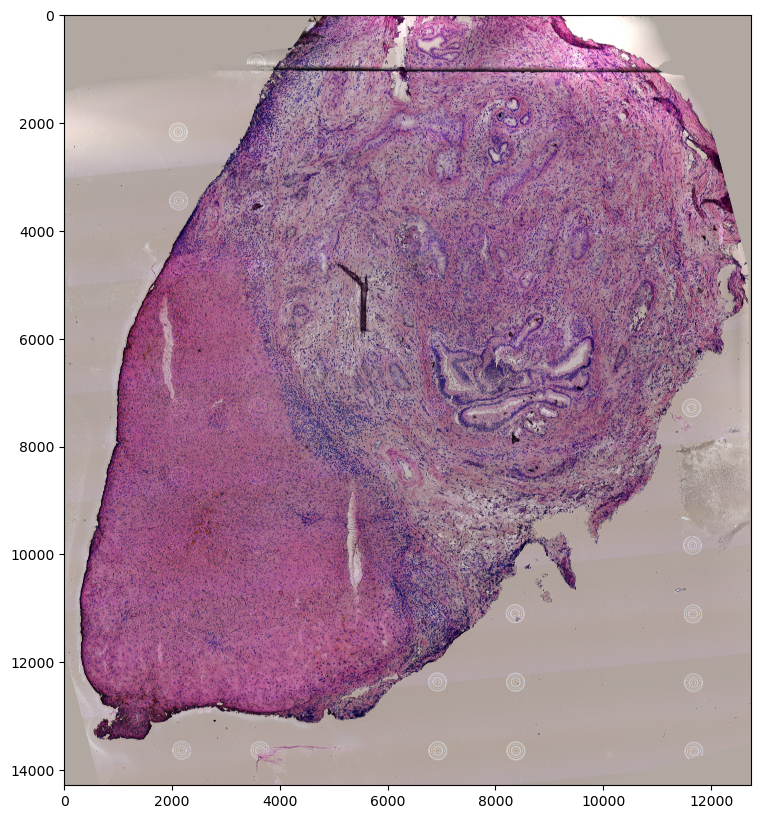

In [10]:
img = adata_spot.uns['staining_image'].transpose((1, 0, 2))
_, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img)
plt.show()

In [11]:
init_mask = lab.pp.mask_tissue(img, mask_gaussian_blur=5)
dilated_mask = lab.pp.dilated_mask(init_mask, dilation_kernel = 'cross', dilation_step=30)
mask_fill_holes = lab.pp.binary_fill_holes(dilated_mask)
final_mask = lab.pp.filter_mask(mask_fill_holes)

In [13]:
adata_tissue,adata_out = lab.pp.mask_adata(adata_spot, final_mask, spatial_key = 'spatial_manual_fine')

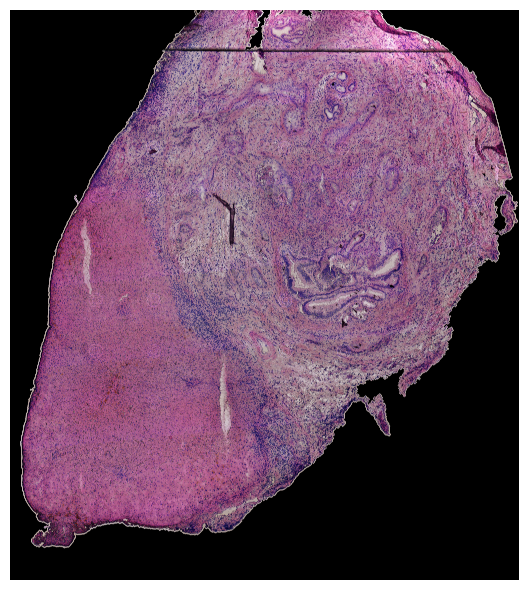

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.imshow(img*final_mask[..., np.newaxis])
ax.axis('off')
plt.tight_layout()
plt.show()

In [14]:
os.makedirs(os.path.join(root_dir,'mask'), exist_ok=True)
np.save(os.path.join(root_dir,'mask/tissue_mask_change.npy'), final_mask)

In [15]:
adata_tissue.uns['final_mask'] = final_mask

In [21]:
os.makedirs(os.path.join(root_dir,'preprocess'), exist_ok=True)
adata_tissue.write(os.path.join(root_dir,'preprocess/mask_tissue.h5ad'))

In [17]:
adata_out.write(os.path.join(root_dir,'preprocess/out_tissue.h5ad'))

In [ ]:
workdir = os.path.join(root_dir,'preprocess')
conda_env = "/Users/yanru/miniforge3/envs/OPENSTT"

segment_cmd = ["conda","run","-p",conda_env,
    "openst", "segment",
    "--image-in", "uns/staining_image",
    "--h5-in", "mask_tissue.h5ad",
    "--mask-out", "uns/staining_image_mask",
    "--model", "HE_cellpose_rajewsky",
    "--flow-threshold", "2",
    "--cellprob-threshold", "-1",
    "--diameter", "20",
    "--device", "cpu",
    "--mask-tissue",
    "--num-workers", "36"
]

assign_cmd = ["conda","run","-p",conda_env,
    "openst", "transcript_assign",
    "--h5-in", "mask_tissue.h5ad",
    "--mask-in", "uns/staining_image_mask",
    "--spatial-key", "obsm/spatial_manual_fine",
    "--h5-out", "cell_segment.h5ad"
]

env = os.environ.copy()
env["MPLBACKEND"] = "Agg"
segment_log = os.path.join(workdir, "openst_segment.log")
assign_log = os.path.join(workdir, "openst_assign.log")

with open(segment_log, "w") as seg_out:
    subprocess.run(segment_cmd, cwd=workdir, env=env, check=True,
                   stdout=seg_out, stderr=seg_out)

with open(assign_log, "w") as assign_out:
    subprocess.run(assign_cmd, cwd=workdir, env=env, check=True,
                   stdout=assign_out, stderr=assign_out)
